# Metric set: correlation and aggregation weights

**Data.** `results.csv`: the same 220 lattices $\times$ 8 algorithms $=$ 1760 drawings as `results.ipynb`.
Rankings are built exactly as there: within-lattice ranks (1 = best, average ranks for ties, scores rounded to $10^{-9}$),
mean rank per context type, context types weighted equally; *Avg.* = metric ranks averaged within each family, then equally across families.

Outputs: `figures/correlation.pdf`, `tables/sensitivity_weights.tex`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
sys.path.insert(0, str(ROOT))

OUT = ROOT / 'analysis'
FIG, TAB = OUT / 'figures', OUT / 'tables'
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.precision', 3)
SEED = 20261102

METRICS = {   # column -> (short, family), in paper order
    'edge_crossing':          ('EC', 'Crossings'),
    'crossing_angle':         ('CA', 'Crossings'),
    'layer_consistency':      ('LC', 'Layering'),
    'vertical_axis_balance':  ('SY', 'Layering'),
    'slope_verticality':      ('FE', 'Slopes'),
    'slope_economy':          ('SE', 'Slopes'),
    'slope_parallelism':      ('SP', 'Slopes'),
    'edge_length_uniformity': ('EH', 'Slopes'),
    'slope_standard':         ('SC', 'Slopes'),
    'visual_chain_linearity': ('CL', 'Slopes'),
    'node_edge_conflict':     ('NE', 'Clearance'),
    'node_node_conflict':     ('NN', 'Clearance'),
    'edge_edge_conflict':     ('EE', 'Clearance'),
    'nested_suitability':     ('NS', 'Clearance'),
}
MS = [v[0] for v in METRICS.values()]
FAMILY = {v[0]: v[1] for v in METRICS.values()}
FAMILIES = ['Crossings', 'Layering', 'Slopes', 'Clearance']
FAM_OF = {f: [m for m in MS if FAMILY[m] == f] for f in FAMILIES}

ALGOS = {'aeschlimann_schmid': 'Less Ink', 'cole_ducrou_eklund': 'CDE', 'dimdraw': 'DimDraw', 'dimflux': 'DimFlux',
         'fdp': 'FDP', 'freese': 'Freese', 'redraw': 'ReDraw', 'sugiyama': 'Sugiyama'}
AL = list(ALGOS.values())
DATASETS = {'m4': 'M4', 'random': 'Random', 'real_world_reduced': 'Real-world', 'theory': 'Theory'}
DS = list(DATASETS.values())

INK, MUTED = '#2b2b29', '#4a4a46'
DIVERGING = LinearSegmentedColormap.from_list('div2', ['#1c5cab', '#5598e7', '#b7d3f6', '#f2f1ee',
                                                      '#f6c4bf', '#e8807c', '#c23b3b'])

mpl.rcParams.update({
    'font.family': 'Inter', 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
    'legend.fontsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#6b6b66', 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'grid.color': '#e4e3df', 'grid.linewidth': 0.5,
})
COL_W = 3.33   # inches

## Data

In [2]:
res = pd.read_csv(ROOT / 'results.csv', dtype={'lattice': str})
res = res.rename(columns={c: v[0] for c, v in METRICS.items()})
res['algorithm'] = res['algorithm'].map(ALGOS); res['ds'] = res['dataset'].map(DATASETS)
res['key'] = res['ds'] + '/' + res['lattice']
res = res.sort_values(['key', 'algorithm']).reset_index(drop=True)
res[MS] = res[MS].round(9)

keys = sorted(res['key'].unique())
assert (res.groupby('key')['algorithm'].nunique() == len(AL)).all()
assert res[MS].notna().all().all() and ((res[MS] >= 0) & (res[MS] <= 1)).all().all()
N, K, M = len(keys), len(AL), len(MS)
cat = np.array([k.split('/')[0] for k in keys])     # context type per lattice

def to_wide(df, cols=MS):
    '''{metric: lattice x algorithm} from a long frame with columns key, algorithm, <metrics>.'''
    return {m: df.pivot(index='key', columns='algorithm', values=m).loc[keys, AL] for m in cols}

def within_ranks(w):
    return w.round(9).rank(axis=1, ascending=False, method='average')

def mean_rank(w):
    '''algorithm -> mean within-lattice rank, context types weighted equally (as in results.ipynb).'''
    r = within_ranks(w)
    return pd.concat([r[cat == d].mean() for d in DS], axis=1).mean(axis=1)

def overall(mr):
    '''Overall score per algorithm from an algorithm x metric mean-rank table (lower = better), families weighted equally.'''
    return pd.DataFrame({f: mr[c].mean(axis=1) for f, c in FAM_OF.items()}).mean(axis=1)

wide = to_wide(res)
MR = pd.DataFrame({m: mean_rank(wide[m]) for m in MS})          # algorithm x metric
AVG = overall(MR)
print(f'{N} lattices x {K} algorithms = {len(res)} drawings; overall ranking:', AVG.sort_values().round(2).to_dict())

220 lattices x 8 algorithms = 1760 drawings; overall ranking: {'DimDraw': 3.95, 'DimFlux': 4.02, 'CDE': 4.17, 'Freese': 4.34, 'Sugiyama': 4.44, 'FDP': 4.68, 'Less Ink': 4.99, 'ReDraw': 5.41}


## Correlation

* **Within-lattice** $\rho_W$ (lower triangle): Pearson correlation of the within-lattice ranks, pooled over lattices
  (each lattice's ranks are centred at $(K+1)/2$, so between-lattice differences are removed; a rank-based repeated-measures correlation).
  $\rho_W(X,Y)<0$ means: on the same lattice, drawings that are better on $X$ tend to be worse on $Y$, i.e. a trade-off.
* **Between-lattice** $\rho_B$ (upper triangle): Spearman correlation of the per-lattice means over the 8 algorithms ($N=220$).

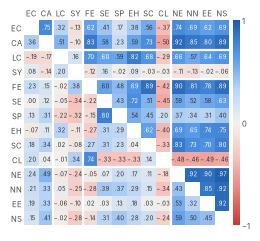

In [3]:
def centred_ranks(w):
    '''N x K x M array of within-lattice ranks, centred per lattice.'''
    return np.stack([within_ranks(w[m]).values for m in MS], axis=-1) - (K + 1) / 2

D = centred_ranks(wide)
S = np.einsum('nkm,nkl->ml', D, D); d = np.sqrt(np.diag(S))
rho_W = pd.DataFrame(S / np.outer(d, d), index=MS, columns=MS)
rho_B = pd.DataFrame({m: wide[m].mean(axis=1) for m in MS}).corr('spearman')

def corr_heatmap(lower, upper, fname):
    '''Lower triangle = `lower`, upper triangle = `upper`; family blocks outlined; value printed in each cell.'''
    fig, ax = plt.subplots(figsize=(COL_W, COL_W * 0.8))
    A = np.tril(lower.values, -1) + np.triu(upper.values, 1)
    np.fill_diagonal(A, np.nan)
    im = ax.imshow(A, cmap=DIVERGING.reversed(), norm=Normalize(-1, 1))
    for i in range(M):
        for j in range(M):
            if i != j:
                v = A[i, j]
                ax.text(j, i, f'{v:.2f}'.replace('0.', '.').replace('-.', '−.'), ha='center', va='center',
                        fontsize=4.2, color='white' if abs(v) > 0.6 else INK)
    bounds = np.cumsum([len(FAM_OF[f]) for f in FAMILIES])[:-1] - 0.5
    for b in bounds:
        ax.axhline(b, color='white', lw=1.6); ax.axvline(b, color='white', lw=1.6)
    ax.set_xticks(range(M), MS); ax.set_yticks(range(M), MS)
    ax.tick_params(length=0); ax.xaxis.tick_top()
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(labelsize=5.5, pad=1.5)
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.015, aspect=30, ticks=[-1, 0, 1])
    cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=5.5, pad=1.5)
    fig.savefig(FIG / f'{fname}.pdf'); plt.show()

corr_heatmap(rho_W, rho_B, 'correlation')

## Aggregation weights

The overall ranking (*Avg.*) weights the four families equally. **Rank acceptability**: metric (resp. family) weights drawn
from a flat Dirichlet ($10^4$ samples; every weight vector equally likely), share of samples in which each algorithm takes
each overall rank (SMAA-style, Lahdelma et al. 1998).

In [4]:
base_order = AVG.sort_values().index
rng = np.random.default_rng(SEED)
Wd = rng.dirichlet(np.ones(M), 10_000)
place = stats.rankdata(Wd @ MR[MS].T.values, axis=1, method='min')       # samples x algorithms
accept = pd.DataFrame({r: (place == r).mean(0) for r in range(1, K + 1)}, index=AL).loc[base_order]
Wf = rng.dirichlet(np.ones(len(FAMILIES)), 10_000)
fam_mr = pd.DataFrame({f: MR[c].mean(axis=1) for f, c in FAM_OF.items()})
place_f = stats.rankdata(Wf @ fam_mr.T.values, axis=1, method='min')
accept_f = pd.DataFrame({r: (place_f == r).mean(0) for r in range(1, K + 1)}, index=AL).loc[base_order]

# Table: both weightings side by side; per algorithm expected rank and share of samples at rank 1, ranks 1-3, rank K
def accept_summary(A):
    return pd.DataFrame({'E': (A * A.columns).sum(axis=1), 'first': A[1], 'top3': A[[1, 2, 3]].sum(axis=1), 'last': A[K]})
wt = pd.concat({'metric': accept_summary(accept), 'family': accept_summary(accept_f)}, axis=1)
wt.insert(0, ('', 'default'), AVG.rank().reindex(wt.index))
display(wt.round(2))

best = {c: (wt[c].min() if c[1] in ('E', 'last') else wt[c].max()) for c in wt.columns if c[0]}
def cell(c, v):
    s = f'{v:.2f}' if c[1] == 'E' else f'{100 * v:.0f}'
    return r'\textbf{%s}' % s if c[0] and c[1] != 'last' and abs(v - best[c]) < 1e-12 else s
lines = [r'\setlength{\tabcolsep}{3pt}',   # tabular* stretches the gaps to exactly the column width
         r'\begin{tabular*}{\columnwidth}{@{\extracolsep{\fill}}l' + 'rrrr' * 2 + '@{}}', r'\toprule',
         r' & \multicolumn{4}{c}{Metric weights} & \multicolumn{4}{c}{Family weights} \\',
         r'\cmidrule(lr){2-5} \cmidrule(lr){6-9}',
         r'Algorithm & ' + ' & '.join([r'$\mathbb{E}[r]$', r'$r{=}1$', r'$r{\le}3$', f'$r{{=}}{K}$'] * 2) + r' \\',
         r'\midrule']
for a, row in wt.iterrows():
    lines.append(' & '.join([a] + [cell(c, row[c]) for c in wt.columns if c[0]]) + r' \\')
lines += [r'\bottomrule', r'\end{tabular*}']
_ = (TAB / 'sensitivity_weights.tex').write_text('\n'.join(lines) + '\n')

metric                   family                  
          default      E first  top3  last      E first  top3  last
algorithm                                                          
DimDraw       1.0   2.43  0.37  0.75  0.00   2.06  0.27  0.91  0.00
DimFlux       2.0   2.61  0.17  0.79  0.00   2.67  0.41  0.71  0.00
CDE           3.0   1.98  0.44  0.90  0.00   2.93  0.11  0.66  0.00
Freese        4.0   5.15  0.02  0.19  0.00   4.03  0.21  0.40  0.00
Sugiyama      5.0   4.14  0.00  0.29  0.00   4.54  0.00  0.11  0.00
FDP           6.0   5.05  0.00  0.08  0.00   5.42  0.00  0.14  0.05
Less Ink      7.0   7.01  0.00  0.00  0.32   6.54  0.00  0.07  0.16
ReDraw        8.0   7.62  0.00  0.00  0.68   7.79  0.00  0.00  0.79